<h1 id="Seq2Seq-Learning-&amp;-Neural-Machine-Translation"><center>Seq2Seq Learning &amp; Neural Machine Translation</center></h1><center>Shan-Hung Wu &amp; DataLab</center>
<center>Fall 2026</center>

<p>Sequence to sequence learning (Seq2Seq) is about training models to convert sequences from one domain (e.g. sentences in Chinese) to sequences in another domain (e.g. the same sentences translated to English). This can be used for machine translation, free-form question answering (generating a natural language answer given a natural language question), text summarization, and image captioning. In general, it is applicable any time you need to generate text.</p>
<p>In this lab, we will introduce how to train a seq2seq model for Chinese to English translation. After training the model in this notebook, you will be able to input a Chinese sentence, such as "你今晚會去派對嗎?", and return the English translation: "will you go to the party tonight?".</p>
<p>The translation quality is reasonable for a toy example, but the generated attention plot is perhaps more interesting. This shows which parts of the input sentence has the model's attention while translating:</p>
<img alt="No description has been provided for this image" src="./imgs/chinese_english_translation.png"/>

<h1><center>Seq2Seq Learning<center></center></center></h1>
<h2 id="Encoder-Decoder-Architecture">Encoder-Decoder Architecture</h2><p>The encoder-decoder architecture is a neural network design pattern. In this architecture, the network is partitioned into two parts, the encoder and the decoder. <strong>The encoder’s role is encoding the inputs into hidden state, or hidden representation</strong>, which often contains several tensors. <strong>Then the hidden state is passed into the decoder to generate the outputs</strong>.</p>
<img alt="No description has been provided for this image" src="./imgs/encoder_to_decoder.png"/>
<h2 id="Sequence-to-Sequence">Sequence to Sequence</h2><p>The sequence to sequence (seq2seq) model is based on the encoder-decoder architecture to generate a sequence output for a sequence input, where both the encoder and the decoder tend to both be recurrent neural networks (RNNs). The hidden state of the encoder is used directly to initialize the hidden state of decoder, bringing information from the encoder to the decoder. In machine translation, the encoder transforms a source sentence, i.e. “你今晚會去派對嗎?”, into hidden state, which is a vector, that captures its semantic information. The decoder then uses this state to generate the translated target sentence, e.g. “will you go to the party tonight?”.</p>
<img alt="No description has been provided for this image" src="./imgs/seq2seq.png"/>
<h2 id="Sequence-to-Sequence-with-Attention-Mechanism">Sequence to Sequence with Attention Mechanism</h2><p>Now, let’s talk about the <strong>attention mechanism</strong>. What is it and why do we need it?</p>
<p>Let’s use Neural Machine Translation (NMT) as an example. In NMT, the encoder maps the meaning of a sentence into <strong>a fixed-length hidden representation</strong>, this representation is expected to be a good summary of the entire input sequence, where the decoder can generate a corresponding translation based on that vector.</p>
<p>A critical and apparent disadvantage of this fixed-length context vector design is the <strong>incapability of the system to remember longer sequences</strong>. It is common to see that the fixed-length vector forgot the earlier parts of the input sentence once it has processed the entire input. A solution we proposed in <a href="https://arxiv.org/abs/1409.0473">Bahdanau et al., 2014</a> and <a href="https://arxiv.org/abs/1508.04025">Luong et al., 2015.</a>. These papers introduced and refined a technique called <strong>Attention</strong>, which highly improved the quality of machine translation systems. Attention allows the model to focus on the relevant parts of the input sequence as needed.</p>
<p>That was the idea behind <strong>Attention</strong>! It can be illustrated as follows:</p>
<img alt="No description has been provided for this image" src="./imgs/seq2seq_attention.gif"/>

## Details of attention

Notations:

- $T_x$: the length of the input
- $h_j$: the $j_{th}$ hidden state of the encoder
- $s_i$: the $i_{th}$ hidden state of the decoder
- $c_i$: context vector, a sum of hidden states of the input sequence, weighted by alignment scores
- $a$: alignment(match) score function, calculate the match score between two vectors($s_{i-1}$ and $h_j$)
- $e_{ij}$: alignment(match) score between the $s_{i-1}$ and $h_j$
- $\alpha_{ij}$: softmax of the alignment(match) score

<img alt="No description has been provided for this image" src="./imgs/illustrated_attention.png"/>
<p>And there are many types of score function:</p>
<img alt="No description has been provided for this image" src="./imgs/score_functions.png"/>
<p>For more details, please read this blog: <a href="https://towardsdatascience.com/attn-illustrated-attention-5ec4ad276ee3">Attn: Illustrated Attention</a></p>
<h2 id="GRU">Gated Recurrent Unit (GRU)</h2>
<img alt="No description has been provided for this image" src="./imgs/Gated_Recurrent_Unit.png"/>
<h2 id="Teacher-Forcing">Teacher Forcing</h2><p>Teacher forcing is an efficient and effective method used widely in the training process of recurrent neural networks, which uses the ground truth from a previous time step as the input to the next time step.</p>

<h1><center>Neural Machine Translation<center></center></center></h1>
<p>Next, we will show how to train a seq2seq model using a translation dataset (Chinese to English), and then we will demonstrate some results of the translation to evaluate the model. In this lab, we will use GRU layers.</p>

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, random_split
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import unicodedata
import re
import numpy as np
import time

from matplotlib.font_manager import FontProperties

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


<h2 id="Prepare-the-dataset">Prepare the dataset</h2>

In [2]:
# dataset path
# use the Chinese-English dataset
path_to_file = "./data/eng-chinese.txt"

<h2 id="Data-preprocessing">Data preprocessing</h2><ol>
<li>Add a <em>start</em> and <em>end</em> token to each sentence.</li>
<li>Clean the sentences by removing special characters.</li>
<li>Create a word index and reverse word index (dictionaries mapping from word → id and id → word).</li>
<li>Pad each sentence to a maximum length.</li>
</ol>

In [3]:
def unicode_to_ascii(s):
    return ''.join(c for c in unicodedata.normalize('NFD', s)
                   if unicodedata.category(c) != 'Mn')


def preprocess_eng(w):
    w = unicode_to_ascii(w.lower().strip())

    # creating a space between a word and the punctuation following it
    # eg: "he is a boy." => "he is a boy ."
    w = re.sub(r"([?.!,])", r" \1 ", w)
    # replace several spaces with one space
    w = re.sub(r'[" "]+', " ", w)

    # replacing everything with space except (a-z, A-Z, ".", "?", "!", ",")
    w = re.sub(r"[^a-zA-Z?.!,]+", " ", w)
    w = w.rstrip().strip()

    # adding a start and an end token to the sentence
    # so that the model know when to start and stop predicting.
    w = '<start> ' + w + ' <end>'
    return w


def preprocess_chinese(w):
    w = unicode_to_ascii(w.lower().strip())
    w = re.sub(r'[" "]+', "", w)
    w = w.rstrip().strip()
    w = " ".join(list(w))  # add the space between words
    w = '<start> ' + w + ' <end>'
    return w

In [4]:
# u means unicode encoder
en_sentence = u"May I borrow this book?"
chn_sentence = u"我可以借這本書麼？"
print(preprocess_eng(en_sentence))
print(preprocess_chinese(chn_sentence))
print(preprocess_chinese(chn_sentence).encode('utf-8'))

<start> may i borrow this book ? <end>
<start> 我 可 以 借 這 本 書 麼 ？ <end>
b'<start> \xe6\x88\x91 \xe5\x8f\xaf \xe4\xbb\xa5 \xe5\x80\x9f \xe9\x80\x99 \xe6\x9c\xac \xe6\x9b\xb8 \xe9\xba\xbc \xef\xbc\x9f <end>'


In [5]:
# 1. Remove the accents
# 2. Clean the sentences
# 3. Return word pairs in the format: [ENGLISH, CHINESE]
def create_dataset(path, num_examples=None):
    lines = open(path, encoding='UTF-8').read().strip().split('\n')
    word_pairs = [[w for w in l.split('\t')] for l in lines[:num_examples]]
    word_pairs = [[preprocess_eng(w[0]), preprocess_chinese(w[1])]
                  for w in word_pairs]

    # return two tuple: one tuple includes all English sentenses, and
    # another tuple includes all Chinese sentenses
    return word_pairs


word_pairs = create_dataset(path_to_file)
# show the first twenty examples
word_pairs[:20]

[['<start> hi . <end>', '<start> 嗨 。 <end>'],
 ['<start> hi . <end>', '<start> 你 好 。 <end>'],
 ['<start> run . <end>', '<start> 你 用 跑 的 。 <end>'],
 ['<start> wait ! <end>', '<start> 等 等 ！ <end>'],
 ['<start> hello ! <end>', '<start> 你 好 。 <end>'],
 ['<start> i try . <end>', '<start> 让 我 来 。 <end>'],
 ['<start> i won ! <end>', '<start> 我 赢 了 。 <end>'],
 ['<start> oh no ! <end>', '<start> 不 会 吧 。 <end>'],
 ['<start> cheers ! <end>', '<start> 乾 杯 ! <end>'],
 ['<start> he ran . <end>', '<start> 他 跑 了 。 <end>'],
 ['<start> hop in . <end>', '<start> 跳 进 来 。 <end>'],
 ['<start> i lost . <end>', '<start> 我 迷 失 了 。 <end>'],
 ['<start> i quit . <end>', '<start> 我 退 出 。 <end>'],
 ['<start> i m ok . <end>', '<start> 我 沒 事 。 <end>'],
 ['<start> listen . <end>', '<start> 听 着 。 <end>'],
 ['<start> no way ! <end>', '<start> 不 可 能 ！ <end>'],
 ['<start> no way ! <end>', '<start> 没 门 ！ <end>'],
 ['<start> really ? <end>', '<start> 你 确 定 ？ <end>'],
 ['<start> try it . <end>', '<start> 试 试 吧 。 <end>'],
 ['

In [6]:
en, chn = zip(*create_dataset(path_to_file))
print(en[-1])
print(chn[-1])
# show the size of the dataset
assert len(en) == len(chn)
print("Size:", len(en))

<start> if a person has not had a chance to acquire his target language by the time he s an adult , he s unlikely to be able to reach native speaker level in that language . <end>
<start> 如 果 一 個 人 在 成 人 前 沒 有 機 會 習 得 目 標 語 言 ， 他 對 該 語 言 的 認 識 達 到 母 語 者 程 度 的 機 會 是 相 當 小 的 。 <end>
Size: 20289


In [ ]:
from collections import Counter
from torch.nn.utils.rnn import pad_sequence

PAD_ID = 0
UNK_ID = 1


class Vocabulary:
    """Build token/ID mappings; max_size includes reserved tokens."""

    def __init__(self, texts=(), max_size=None, lower=False, use_unk=True):
        self.lower = lower
        self.use_unk = use_unk
        reserved_tokens = ["<pad>", "<unk>"] if use_unk else ["<pad>"]
        if max_size is not None and max_size < len(reserved_tokens):
            raise ValueError("max_size must include all reserved tokens")

        self.index_to_token = list(reserved_tokens)
        self.token_to_index = {
            token: index for index, token in enumerate(self.index_to_token)
        }
        self.token_counts = Counter()

        for text in texts:
            self.add_sentence(text)

        if max_size is not None:
            tokens = [token for token, _ in self.token_counts.most_common(max_size - len(reserved_tokens))]
            self.index_to_token = reserved_tokens + tokens
            self.token_to_index = {
                token: index for index, token in enumerate(self.index_to_token)
            }

    def add_sentence(self, text):
        """Split a cleaned sentence and add its tokens in order."""
        for token in (text.lower() if self.lower else text).split():
            self.add_token(token)

    def add_token(self, token):
        """Count a token and assign an ID when it first appears."""
        if token in {"<pad>", "<unk>"}:
            return
        self.token_counts[token] += 1
        if token not in self.token_to_index:
            self.token_to_index[token] = len(self.index_to_token)
            self.index_to_token.append(token)

    def __len__(self):
        return len(self.index_to_token)

    def encode(self, text):
        tokens = (text.lower() if self.lower else text).split()
        if self.use_unk:
            ids = [self.token_to_index.get(token, UNK_ID) for token in tokens]
        else:
            ids = [self.token_to_index[token] for token in tokens
                   if token in self.token_to_index]
        return torch.tensor(ids, dtype=torch.long)


def pad_encoded_sequences(sequences, max_length=None):
    """Right-pad token tensors; optionally keep only the last max_length IDs."""
    if max_length is not None:
        sequences = [seq[-max_length:] for seq in sequences]
    padded = pad_sequence(sequences, batch_first=True, padding_value=PAD_ID)
    if max_length is not None:
        # pad_sequence pads to the longest sequence, not a requested fixed length.
        padded = F.pad(padded, (0, max_length - padded.size(1)), value=PAD_ID)
    return padded


In [8]:
def tokenize(lang):
    lang = list(lang)
    # Build the vocabulary sentence by sentence.
    vocab = Vocabulary()
    for text in lang:
        vocab.add_sentence(text)

    # Encode each sentence with the completed vocabulary.
    sequences = [vocab.encode(text) for text in lang]

    # Right-pad sentences to the longest sentence in this language.
    tensor = pad_sequence(sequences, batch_first=True, padding_value=PAD_ID)
    return tensor, vocab


def load_dataset(path, num_examples=None):
    # Chinese is the source language; English is the target language.
    targ_lang, inp_lang = zip(*create_dataset(path, num_examples))

    input_tensor, inp_vocab = tokenize(inp_lang)
    target_tensor, targ_vocab = tokenize(targ_lang)

    return input_tensor, target_tensor, inp_vocab, targ_vocab


In [9]:
# Set num_examples = 10000 for a smaller dataset; None uses all pairs.
num_examples = None
input_tensor, target_tensor, inp_lang, targ_lang = load_dataset(
    path_to_file, num_examples)

# Padded tensors have shape (number of sentences, sequence length).
max_length_inp = input_tensor.size(1)
max_length_targ = target_tensor.size(1)

# Split paired sentences into training and validation subsets (95% / 5%).
translation_dataset = TensorDataset(input_tensor, target_tensor)
num_val = (len(translation_dataset) + 19) // 20  # Round 5% up.
num_train = len(translation_dataset) - num_val
train_dataset, val_dataset = random_split(
    translation_dataset,
    [num_train, num_val],
    generator=torch.Generator().manual_seed(42),
)

print(f"# training data: {len(train_dataset)}\n# validation data: {len(val_dataset)}")


# training data: 19274
# validation data: 1015


In [10]:
def convert(vocab, token_ids):
    for token_id in token_ids.tolist():
        if token_id != PAD_ID:
            print(f"{token_id} ----> {vocab.index_to_token[token_id]}")


# A dataset item is one aligned (source, target) pair.
input_example, target_example = train_dataset[0]
print("Input Language; index to word mapping")
convert(inp_lang, input_example)
print()
print("Target Language; index to word mapping")
convert(targ_lang, target_example)


Input Language; index to word mapping
2 ----> <start>
237 ----> t
238 ----> o
239 ----> m
513 ----> 正
162 ----> 在
1002 ----> 喝
832 ----> 果
1003 ----> 汁
4 ----> 。
5 ----> <end>

Target Language; index to word mapping
2 ----> <start>
33 ----> tom
145 ----> is
1782 ----> drinking
849 ----> juice
4 ----> .
5 ----> <end>


<h2 id="Create-a-DataLoader">Create a DataLoader</h2>

In [11]:
BATCH_SIZE = 128
embedding_dim = 256
units = 1024
# Vocabulary sizes already include <pad> and <unk>.
vocab_inp_size = len(inp_lang)
vocab_tar_size = len(targ_lang)

# Use the training subset created by random_split above.
dataset = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
steps_per_epoch = len(dataset)

example_input_batch, example_target_batch = next(iter(dataset))
example_input_batch.shape, example_target_batch.shape

(torch.Size([128, 46]), torch.Size([128, 38]))

<h2 id="Encoder">Encoder</h2>

In [12]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, enc_units, batch_sz):
        # vocab_size includes <pad> and <unk>; dimensions come from constructor arguments.
        super().__init__()
        self.batch_sz = batch_sz
        self.enc_units = enc_units
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.gru = nn.GRU(embedding_dim, enc_units, batch_first=True)

    def forward(self, x, hidden):
        # x: (batch_size, sequence_length), for translation or sentiment analysis
        # hidden: (batch_size, enc_units)
        # after embedding, x: (batch_size, sequence_length, embedding_dim)
        x = self.embedding(x)

        # output: (batch_size, sequence_length, enc_units)
        # raw GRU state: (1, batch_size, enc_units); returned state: (batch_size, enc_units)
        # (nn.GRU wants/returns hidden as (num_layers, batch, units), hence the
        # unsqueeze/squeeze -- there's exactly one layer here)
        output, state = self.gru(x, hidden.unsqueeze(0))

        return output, state.squeeze(0)

    def initialize_hidden_state(self):
        # initial hidden: (batch_sz, enc_units); forward adds the GRU layer dimension.
        return torch.zeros(self.batch_sz, self.enc_units, device=device)

In [13]:
encoder = Encoder(vocab_inp_size, embedding_dim, units, BATCH_SIZE).to(device)

# sample input
example_input_batch = example_input_batch.to(device)
sample_hidden = encoder.initialize_hidden_state()
sample_output, sample_hidden = encoder(example_input_batch, sample_hidden)
print('Encoder output shape: (batch size, sequence length, units) {}'.format(tuple(sample_output.shape)))
print('Encoder Hidden state shape: (batch size, units) {}'.format(tuple(sample_hidden.shape)))

# the output and the hidden state of GRU is equal
print(sample_output[-1, -1, :] == sample_hidden[-1, :])

Encoder output shape: (batch size, sequence length, units) (128, 46, 1024)
Encoder Hidden state shape: (batch size, units) (128, 1024)
tensor([True, True, True,  ..., True, True, True], device='cuda:0')


## Attention

In this lab, we use the **Bahdanau Attention** as our attention mechanism. The formula of score function in Bahdanau Attention is:

$$
\text{score}(s_t, h_i) = v_a^T \tanh\left(W_a[s_t; h_i]\right)
$$

In [14]:
class BahdanauAttention(nn.Module):
    def __init__(self, units, hidden_size):
        super().__init__()
        self.W1 = nn.Linear(hidden_size, units)
        self.W2 = nn.Linear(hidden_size, units)
        self.V = nn.Linear(units, 1)

    def forward(self, query, values):
        # query: (batch_size, hidden_size); values: (batch_size, sequence_length, hidden_size)
        # hidden_with_time_axis: (batch_size, 1, hidden_size)
        # we are doing this to perform addition to calculate the score
        hidden_with_time_axis = query.unsqueeze(1)

        # score shape == (batch_size, sequence_length, 1)
        score = self.V(torch.tanh(self.W1(values) + self.W2(hidden_with_time_axis)))

        # attention_weights shape == (batch_size, sequence_length, 1)
        attention_weights = F.softmax(score, dim=1)

        # context_vector shape == (batch_size, sequence_length, hidden_size)
        context_vector = attention_weights * values

        # context_vector shape after sum == (batch_size, hidden_size)
        context_vector = context_vector.sum(dim=1)

        return context_vector, attention_weights

In [15]:
attention_layer = BahdanauAttention(10, hidden_size=units).to(device)
attention_result, attention_weights = attention_layer(sample_hidden, sample_output)

print("Attention result shape: (batch size, units) {}".format(tuple(attention_result.shape)))
print("Attention weights shape: (batch_size, sequence_length, 1) {}".format(tuple(attention_weights.shape)))

Attention result shape: (batch size, units) (128, 1024)
Attention weights shape: (batch_size, sequence_length, 1) (128, 46, 1)


<h2 id="Decoder">Decoder</h2>

In [16]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, dec_units, batch_sz):
        # vocab_size = len(targ_lang), including <pad> and <unk>.
        super().__init__()
        self.batch_sz = batch_sz
        self.dec_units = dec_units
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.gru = nn.GRU(embedding_dim + dec_units, dec_units, batch_first=True)
        # the dimension of the output is the vocab size; nn.CrossEntropyLoss
        # applies softmax internally, so we return logits here
        self.fc = nn.Linear(dec_units, vocab_size)

        # used for attention
        self.attention = BahdanauAttention(dec_units, dec_units)

    def forward(self, x, hidden, enc_output):
        # This function outputs a result at each timestamp
        # The hidden state of the first timestamp in the decoder is
        # the hidden state of the last timestamp in the encoder
        context_vector, attention_weights = self.attention(hidden, enc_output)

        # x shape after passing through embedding == (batch_size, 1, embedding_dim)
        x = self.embedding(x)

        # concatenate the input x and the context_vector, as the input of the GRU
        # context_vector: (batch_size, dec_units)
        # x after concatenation: (batch_size, 1, dec_units + embedding_dim)
        x = torch.cat([context_vector.unsqueeze(1), x], dim=-1)

        # passing the concatenated vector to the GRU
        # output: (batch_size, 1, dec_units)
        # raw GRU state: (1, batch_size, dec_units); returned state: (batch_size, dec_units)
        output, state = self.gru(x, hidden.unsqueeze(0))

        # flattened output: (batch_size, dec_units)
        output = output.reshape(-1, output.shape[2])

        # logits after self.fc: (batch_size, vocab_size)
        x = self.fc(output)

        return x, state.squeeze(0), attention_weights

In [17]:
decoder = Decoder(vocab_tar_size, embedding_dim, units, BATCH_SIZE).to(device)
sample_decoder_output, _, _ = decoder(
    torch.randint(0, vocab_tar_size, (BATCH_SIZE, 1), device=device), sample_hidden, sample_output)
print('Decoder output shape: (batch_size, vocab size) {}'.format(tuple(sample_decoder_output.shape)))

Decoder output shape: (batch_size, vocab size) (128, 6083)


<h2 id="Define-the-optimizer-and-the-loss-function">Define the optimizer and the loss function</h2>

In [18]:
optimizer = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()))

def loss_function(real, pred):
    """Calculate the loss value
    Args:
        real: the true label  shape == (batch_size,)
        pred: the logits of each word from the vocabulary, is the output from the decoder
                 shape == (batch_size, vocab_size)

    Returns:
        the average loss of the data in a batch size
    """
    mask = (real != 0).float()
    loss_ = F.cross_entropy(pred, real, reduction='none')

    loss_ = loss_ * mask

    return loss_.mean()

<h2 id="Checkpoints-(Object-based-saving)">Checkpoints (Object-based saving)</h2>

In [19]:
checkpoint_dir = './checkpoints/chinese-eng'
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_path = os.path.join(checkpoint_dir, 'ckpt.pt')

<h2 id="Training">Training</h2><ol>
<li>Pass the <em>input</em> through the <em>encoder</em> which return <em>encoder output</em> and the <em>encoder hidden state</em>.</li>
<li>The encoder output, encoder hidden state and the decoder input (which is the <em>start token</em>) is passed to the decoder.</li>
<li>The decoder returns the <em>predictions</em> and the <em>decoder hidden state</em>.</li>
<li>The decoder hidden state is then passed back into the model and the predictions are used to calculate the loss.</li>
<li>Use <em>teacher forcing</em> to decide the next input to the decoder.</li>
<li><em>Teacher forcing</em> is the technique where the <em>target word</em> is passed as the next input to the decoder.</li>
<li>The final step is to calculate the gradients and apply it to the optimizer and backpropagate.</li>
</ol>

In [20]:
def train_step(inp, targ, enc_hidden):
    loss = 0.0
    optimizer.zero_grad()

    enc_output, enc_hidden = encoder(inp, enc_hidden)

    dec_hidden = enc_hidden

    # feed the <start> as the first input of the decoder
    # dec input shape == (batch_size, 1)
    dec_input = torch.full((inp.size(0), 1), targ_lang.token_to_index['<start>'],
                            dtype=torch.long, device=device)

    # Teacher forcing - feeding the target as the next input
    # because of the data preprocessing (add a start token to the sentence)
    # the first word is <start>, so t starts from 1 (not 0)
    for t in range(1, targ.shape[1]):
        # passing enc_output to the decoder
        predictions, dec_hidden, _ = decoder(dec_input, dec_hidden, enc_output)

        # targ[:, t] is the true label (index of the word) of every sentence (in a batch)
        # at the current timestamp, shape == (batch_size,)
        # predictions shape == (batch_size, vocab_size)
        loss = loss + loss_function(targ[:, t], predictions)

        # using teacher forcing
        dec_input = targ[:, t].unsqueeze(1)

    batch_loss = loss / targ.shape[1]

    loss.backward()
    optimizer.step()

    return batch_loss.item()

<p><strong>You don't need to train the model by yourself, you can download the model weights <a href="https://drive.google.com/file/d/1R8lstGwtNDzIsvR2uY6bP9suOZhEVbxm/view?usp=drive_link">here</a>.</strong></p>

In [21]:
# set the epochs for training
EPOCHS = 50

for epoch in range(EPOCHS):
    start = time.time()

    # get the initial hidden state of gru
    enc_hidden = encoder.initialize_hidden_state()
    total_loss = 0

    for batch, (inp, targ) in enumerate(dataset):
        if batch >= steps_per_epoch:
            break
        inp, targ = inp.to(device), targ.to(device)
        batch_loss = train_step(inp, targ, enc_hidden)
        total_loss += batch_loss

        if batch % 100 == 0:
            print('Epoch {} Batch {} Loss {:.4f}'.format(epoch + 1, batch, batch_loss))

    # saving (checkpoint) the model every 5 epochs
    if (epoch + 1) % 5 == 0:
        torch.save({'encoder': encoder.state_dict(), 'decoder': decoder.state_dict(),
                    'optimizer': optimizer.state_dict()}, checkpoint_path)

    print('Epoch {} Loss {:.4f}'.format(epoch + 1, total_loss / steps_per_epoch))
    print('Time taken for 1 epoch {} sec\n'.format(time.time() - start))

Epoch 1 Batch 0 Loss 1.9662
Epoch 1 Batch 100 Loss 0.8521
Epoch 1 Loss 0.9326
Time taken for 1 epoch 55.108800649642944 sec

Epoch 2 Batch 0 Loss 0.6385
Epoch 2 Batch 100 Loss 0.5758
Epoch 2 Loss 0.5926
Time taken for 1 epoch 55.55826377868652 sec

Epoch 3 Batch 0 Loss 0.4286
Epoch 3 Batch 100 Loss 0.3959
Epoch 3 Loss 0.3924
Time taken for 1 epoch 55.59520936012268 sec

Epoch 4 Batch 0 Loss 0.2394
Epoch 4 Batch 100 Loss 0.2425
Epoch 4 Loss 0.2397
Time taken for 1 epoch 55.855385541915894 sec

Epoch 5 Batch 0 Loss 0.1303
Epoch 5 Batch 100 Loss 0.1252
Epoch 5 Loss 0.1356
Time taken for 1 epoch 55.27013087272644 sec

Epoch 6 Batch 0 Loss 0.0737
Epoch 6 Batch 100 Loss 0.0642
Epoch 6 Loss 0.0731
Time taken for 1 epoch 55.11840486526489 sec

Epoch 7 Batch 0 Loss 0.0313
Epoch 7 Batch 100 Loss 0.0428
Epoch 7 Loss 0.0396
Time taken for 1 epoch 55.12054467201233 sec

Epoch 8 Batch 0 Loss 0.0226
Epoch 8 Batch 100 Loss 0.0257
Epoch 8 Loss 0.0238
Time taken for 1 epoch 55.12377977371216 sec

Epoch 

<h2 id="Translate">Translate</h2><ul>
<li>The evaluate function is similar to the training loop, except we <strong>don't use teacher forcing</strong> here. The input to the decoder at each time step is its previous predictions along with the hidden state and the encoder output.</li>
<li>Stop predicting when the model predicts the <em>end token</em>.</li>
<li>And store the <em>attention weights for every time step</em>.</li>
</ul>
<h3 id="Note:">Note:</h3><ul>
<li>In the <code>plot_attention function</code>, you need to change the <code>font = FontProperties(fname=r"./data/TaipeiSansTCBeta-Regular.ttf", size=14)</code>, where fname denotes the location of the font, based on your computer. Otherwise, the Chinese character will not be displayed in the plot.</li>
</ul>

In [22]:
@torch.no_grad()
def evaluate(sentence):
    """Translate a sentence
    Args:
        sentence: the test sentence
    """
    encoder.eval(); decoder.eval()

    # attention_plot: (max_length_targ, max_length_inp), from the loaded data
    attention_plot = np.zeros((max_length_targ, max_length_inp))

    sentence = preprocess_chinese(sentence)

    # convert each word to the index in the test sentence
    inputs = pad_encoded_sequences(
        [inp_lang.encode(sentence)], max_length=max_length_inp
    ).to(device)

    result = ''

    # hidden: (1, units), with batch_size=1 for inference
    hidden = torch.zeros(1, units, device=device)

    # enc_out: (1, max_length_inp, units)
    # enc_hidden: (1, units)
    enc_out, enc_hidden = encoder(inputs, hidden)

    dec_hidden = enc_hidden
    dec_input = torch.tensor([[targ_lang.token_to_index['<start>']]], device=device)

    for t in range(max_length_targ):
        predictions, dec_hidden, attention_weights = decoder(dec_input, dec_hidden, enc_out)

        # storing the attention weigths to plot later on
        attention_weights = attention_weights.reshape(-1)
        attention_plot[t] = attention_weights.cpu().numpy()

        # get the index which has the highest probability
        predicted_id = predictions[0].argmax().item()
        # convert the index to the word
        result += targ_lang.index_to_token[predicted_id] + ' '

        # when the decoder predicts the end, stop prediction
        if targ_lang.index_to_token[predicted_id] == '<end>':
            return result, sentence, attention_plot

        # the predicted id is fed back into the model
        dec_input = torch.tensor([[predicted_id]], device=device)

    return result, sentence, attention_plot


# function for plotting the attention weights
def plot_attention(attention, sentence, predicted_sentence):
    # you need to change the fname based on your system, and the Chinese can be displayed in the plot
    font = FontProperties(fname=r"./data/TaipeiSansTCBeta-Regular.ttf", size=14)
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(1, 1, 1)
    ax.matshow(attention, cmap='viridis')

    fontdict = {'fontsize': 14}

    # set the x-tick/y-tick labels with list of string labels
    ax.set_xticklabels([''] + sentence, fontdict=fontdict, fontproperties=font)
    ax.set_yticklabels([''] + predicted_sentence, fontdict=fontdict, fontproperties=font)

    # set tick locators
    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
    plt.show()

def translate(sentence):
    result, sentence, attention_plot = evaluate(sentence)
    print('Input: %s' % (sentence))
    print('Predicted translation: {}'.format(result))

    attention_plot = attention_plot[:len(result.split(' ')), :len(sentence.split(' '))]
    plot_attention(attention_plot, sentence.split(' '), result.split(' '))

<h2 id="Restore-the-latest-checkpoint-and-test">Restore the latest checkpoint and test</h2>

In [23]:
checkpoint_dir = './checkpoints/chinese-eng'
checkpoint_path = os.path.join(checkpoint_dir, 'ckpt.pt')
print(checkpoint_path)

# restoring the latest checkpoint
checkpoint = torch.load(checkpoint_path, map_location=device)
encoder.load_state_dict(checkpoint['encoder'])
decoder.load_state_dict(checkpoint['decoder'])
optimizer.load_state_dict(checkpoint['optimizer'])

./checkpoints/chinese-eng/ckpt.pt


Input: <start> 你 今 晚 會 去 派 對 嗎 ? <end>
Predicted translation: will you go to the party ? <end> 


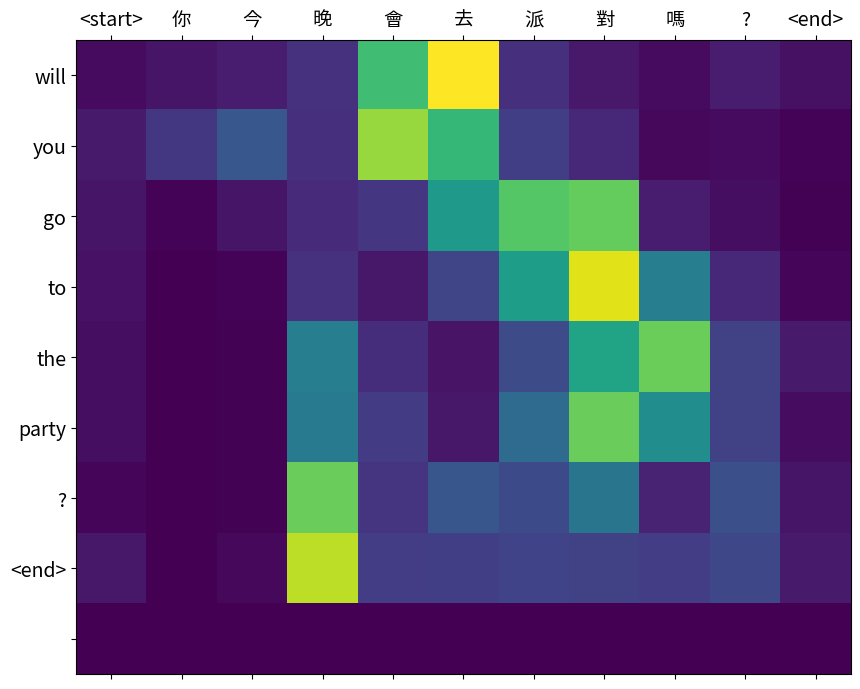

In [24]:
translate('你今晚會去派對嗎?')

Input: <start> 我 有 一 隻 貓 。 <end>
Predicted translation: i have a cat . <end> 


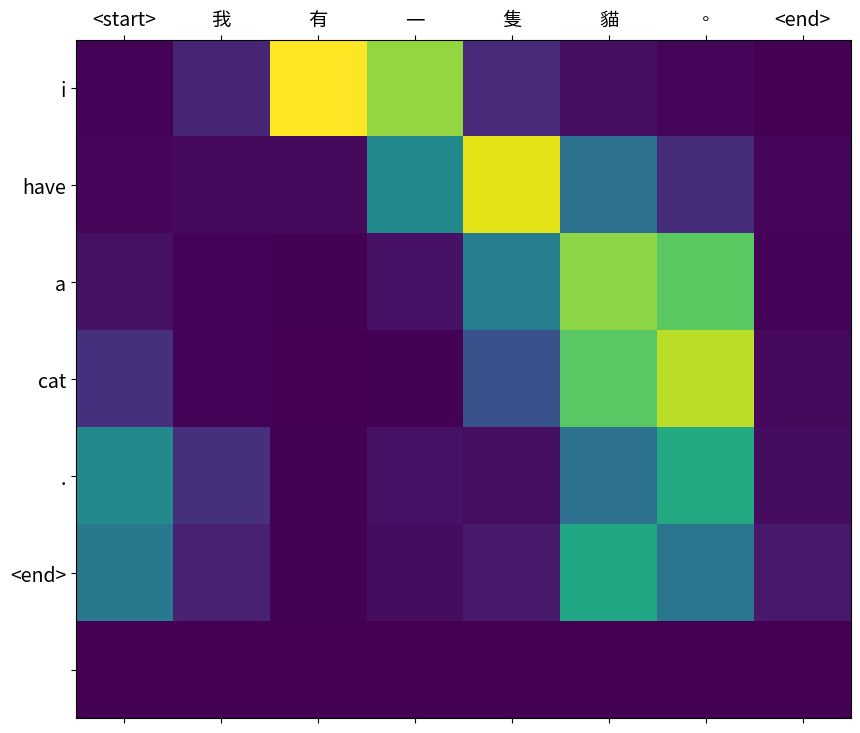

In [25]:
translate('我有一隻貓。')

Input: <start> 她 明 年 會 去 美 國 嗎 ? <end>
Predicted translation: will she go to america next year ? <end> 


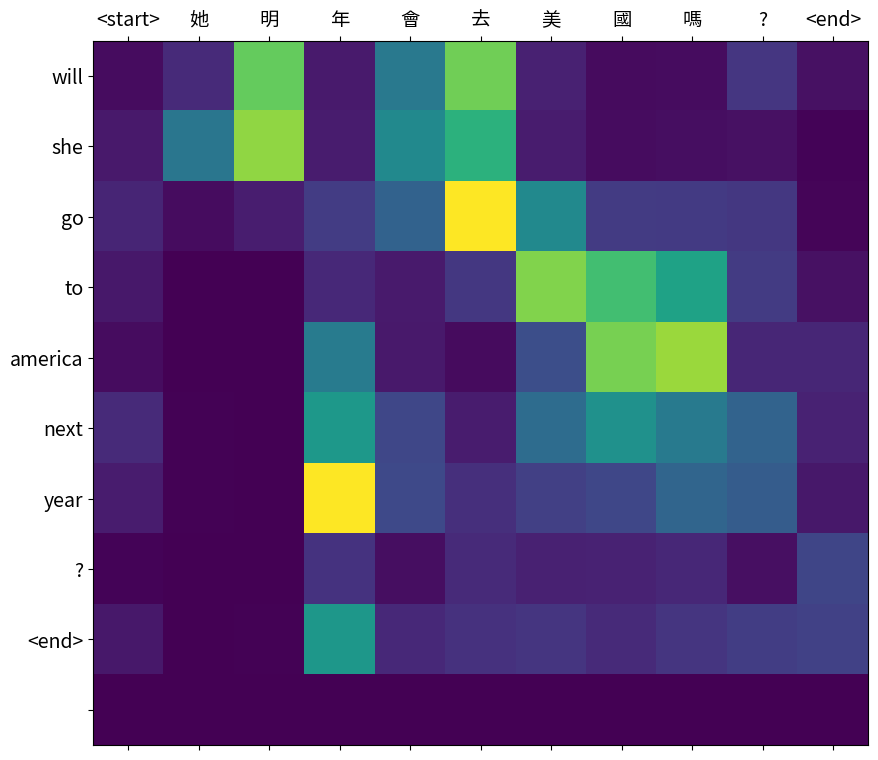

In [26]:
translate('她明年會去美國嗎?')

<h2 id="Reference:">Reference:</h2><ul>
</ul>
<h3 id="Papers:">Papers:</h3><ul>
<li>Seq2seq paper: <a href="https://papers.nips.cc/paper/5346-sequence-to-sequence-learning-with-neural-networks.pdf">Sequence to Sequence Learning with Neural Networks</a></li>
<li>Seq2seq paper: <a href="https://www.aclweb.org/anthology/D14-1179.pdf">Learning Phrase Representations using RNN Encoder–Decoder for Statistical Machine Translation</a></li>
<li>Bahdanau Attention paper: <a href="https://arxiv.org/abs/1409.0473">Neural Machine Translation by Jointly Learning to Align and Translate</a></li>
<li>Luong attention paper: <a href="https://arxiv.org/abs/1508.04025">Effective Approaches to Attention-based Neural Machine Translation</a></li>
<li>Transformer: <a href="https://arxiv.org/abs/1706.03762">Attention Is All You Need</a></li>
<li>BERT: <a href="https://arxiv.org/abs/1810.04805">BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding</a></li>
</ul>
<h3 id="Toturials:">Toturials:</h3><ul>
<li><a href="https://towardsdatascience.com/illustrated-guide-to-lstms-and-gru-s-a-step-by-step-explanation-44e9eb85bf21">Illustrated Guide to LSTM’s and GRU’s: A step by step explanation</a></li>
<li><a href="https://towardsdatascience.com/attn-illustrated-attention-5ec4ad276ee3">Attn: Illustrated Attention</a></li>
<li><a href="http://jalammar.github.io/visualizing-neural-machine-translation-mechanics-of-seq2seq-models-with-attention/">Visualizing A Neural Machine Translation Model (Mechanics of Seq2seq Models With Attention)</a></li>
<li><a href="http://jalammar.github.io/illustrated-transformer/">The Illustrated Transformer</a></li>
<li><a href="http://jalammar.github.io/illustrated-bert/">The Illustrated BERT, ELMo, and co. (How NLP Cracked Transfer Learning)</a></li>
</ul>

<h1 id="Assignment" style="text-align: center;">Assignment</h1>

## Sentiment Analysis

In this assignment, we will train a seq2seq model with **Luong Attention** to solve a sentiment analysis task with the IMDB dataset. The formula of score function in Luong Attention is:

$$
\text{score}(s_t, h_i) = s_t^T W_a h_i
$$

This dataset contains 50,000 sentences with binary labels (positive and negative). Here we split the data into training and test sets. It is worth mentioning that different from the neural machine translation, the decoder used for sentiment analysis is 4-fully-connected layers, rather than GRU layer since here we want to make a binary classification.


In [27]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import pandas as pd
import re
import numpy as np
import os
import time
from sklearn.model_selection import train_test_split

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [28]:
# load the dataset
movie_reviews = pd.read_csv("./data/IMDB Dataset.csv")

<h2 id="Data-preprocessing">Data preprocessing</h2>

In [29]:
movie_reviews.isnull().values.any()

np.False_

In [30]:
movie_reviews.shape

(50000, 2)

In [31]:
movie_reviews.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [32]:
movie_reviews["review"][0]

"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fa

In [33]:
TAG_RE = re.compile(r'<[^>]+>')

def remove_tags(text):
    return TAG_RE.sub('', text)

def preprocess_text(sen):
    # Removing html tags
    sentence = remove_tags(sen)

    # Remove punctuations and numbers
    sentence = re.sub('[^a-zA-Z]', ' ', sentence)

    # Single character removal
    sentence = re.sub(r"\s+[a-zA-Z]\s+", ' ', sentence)

    # Removing multiple spaces
    sentence = re.sub(r'\s+', ' ', sentence)

    return sentence

In [34]:
X = []
sentences = list(movie_reviews['review'])
for sen in sentences:
    X.append(preprocess_text(sen))

# replace the positive with 1, replace the negative with 0
y = movie_reviews['sentiment']
y = np.array(list(map(lambda x: 1 if x == "positive" else 0, y)))

In [35]:
# Split the training dataset and test dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("# training data: {:d}\n# test data: {:d}".format(len(X_train), len(X_test)))

# training data: 40000
# test data: 10000


In [ ]:
vocab = Vocabulary(X_train, max_size=10000, lower=True, use_unk=False)

X_train = [vocab.encode(text) for text in X_train]
X_test = [vocab.encode(text) for text in X_test]

max_len = 100
X_train = pad_encoded_sequences(X_train, max_length=max_len)
X_test = pad_encoded_sequences(X_test, max_length=max_len)


In [37]:
X_train[0]

tensor([   1,  296,  140, 2854,    2,  405,  614,    1,  263,    5, 3514,  977,
           4,   25,   37,   11, 1237,  215,   62,    2,   35,    5,   27,  217,
          24,  189, 1430,    7, 1068,   15, 4868,   81,    1,  221,   63,  351,
          64,   52,   24,    4, 3547,   13,    6,   19,  192,    4, 8148,  859,
        3430, 1720,   17,   23,    4,  158,  194,  175,  106,    9, 1604,  461,
          71,  218,    4,  321,    2, 3431,   31,   20,   47,   68, 1844, 4668,
          11,    6, 1365,    8,   16,    5, 3475, 1990,   14,   59,    1, 2380,
         460,  518,    2,  170, 2524, 2698, 1745,    4,  573,    6,   33,    1,
        3750,  198,  345, 3812])

In [38]:
BUFFER_SIZE = len(X_train)
BATCH_SIZE = 128
steps_per_epoch = len(X_train) // BATCH_SIZE
embedding_dim = 256
units = 1024
# At most 10000 entries: <pad> plus 9999 retained words.
vocab_size = len(vocab)

train_ds = TensorDataset(X_train, torch.from_numpy(y_train).float())
dataset = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

test_ds = TensorDataset(X_test, torch.from_numpy(y_test).float())
test_dataset = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

example_input_batch, example_target_batch = next(iter(dataset))
example_input_batch.shape, example_target_batch.shape

(torch.Size([128, 100]), torch.Size([128]))

In [ ]:
def initialize_weights(module):
    """Initialize embedding, GRU, and linear layer parameters."""
    if isinstance(module, nn.Embedding):
        nn.init.uniform_(module.weight, -0.05, 0.05)
    elif isinstance(module, nn.GRU):
        for name, parameter in module.named_parameters(recurse=False):
            if name.startswith("weight_"):
                nn.init.xavier_uniform_(parameter)
            elif name.startswith("bias_"):
                nn.init.zeros_(parameter)
    elif isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)


# same Encoder class as the NMT section above
encoder = Encoder(vocab_size, embedding_dim, units, BATCH_SIZE).to(device)
encoder.apply(initialize_weights)

# sample input
example_input_batch = example_input_batch.to(device)
sample_hidden = encoder.initialize_hidden_state()
sample_output, sample_hidden = encoder(example_input_batch, sample_hidden)
print('Encoder output shape: (batch size, sequence length, units) {}'.format(tuple(sample_output.shape)))
print('Encoder Hidden state shape: (batch size, units) {}'.format(tuple(sample_hidden.shape)))
# the output and the hidden state of GRU is equal
print(sample_output[-1, -1, :] == sample_hidden[-1, :])

Encoder output shape: (batch size, sequence length, units) (128, 100, 1024)
Encoder Hidden state shape: (batch size, units) (128, 1024)
tensor([True, True, True,  ..., True, True, True], device='cuda:0')


In [ ]:
class LuongAttention(nn.Module):
    def __init__(self, units):
        super().__init__()
        # TODO: Complete the function.
        pass

    def forward(self, query, values):
        # TODO: Implement the Luong attention.
        raise NotImplementedError

In [41]:
class Decoder(nn.Module):
    def __init__(self, dec_units, batch_sz):
        super().__init__()
        self.batch_sz = batch_sz
        self.dec_units = dec_units

        # pass through four fully connected layers, the model will return
        # the logit of the positivity of the sentence
        self.fc_1 = nn.Linear(dec_units, 2048)
        self.fc_2 = nn.Linear(2048, 512)
        self.fc_3 = nn.Linear(512, 64)
        self.fc_4 = nn.Linear(64, 1)

        # used for attention
        self.attention = LuongAttention(self.dec_units)

    def forward(self, hidden, enc_output):
        context_vector, attention_weights = self.attention(hidden, enc_output)
        output = self.fc_1(context_vector)
        output = self.fc_2(output)
        output = self.fc_3(output)
        output = self.fc_4(output)

        return output, attention_weights

In [42]:
decoder = Decoder(units, BATCH_SIZE).to(device)
decoder.apply(initialize_weights)
sample_decoder_output, _ = decoder(sample_hidden, sample_output)
print('Decoder output shape: (batch_size, 1) {}'.format(tuple(sample_decoder_output.shape)))

Decoder output shape: (batch_size, 1) (128, 1)


In [43]:
optimizer = torch.optim.Adam(
    list(encoder.parameters()) + list(decoder.parameters()),
    lr=1e-3, eps=1e-7,
)

def loss_function(real, pred):
    return F.binary_cross_entropy_with_logits(pred, real)

In [44]:
checkpoint_dir = './checkpoints/sentiment-analysis'
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_path = os.path.join(checkpoint_dir, 'ckpt.pt')

In [45]:
def train_step(inp, targ, enc_hidden):
    optimizer.zero_grad()

    enc_output, enc_hidden = encoder(inp, enc_hidden)

    # passing enc_output to the decoder
    predictions, _ = decoder(enc_hidden, enc_output)

    loss = loss_function(targ.unsqueeze(1), predictions)

    loss.backward()
    optimizer.step()

    return loss.item()

In [46]:
# set the epochs for training
EPOCHS = 10

for epoch in range(EPOCHS):
    encoder.train()
    decoder.train()
    start = time.time()

    # get the initial hidden state of gru
    enc_hidden = encoder.initialize_hidden_state()
    total_loss = 0

    for batch, (inp, targ) in enumerate(dataset):
        if batch >= steps_per_epoch:
            break
        inp, targ = inp.to(device), targ.to(device)
        batch_loss = train_step(inp, targ, enc_hidden)
        total_loss += batch_loss

        if batch % 100 == 0:
            print('Epoch {} Batch {} Loss {:.4f}'.format(epoch + 1, batch, batch_loss))

    # saving (checkpoint) the model every 2 epochs
    if (epoch + 1) % 2 == 0:
        torch.save({'encoder': encoder.state_dict(), 'decoder': decoder.state_dict(),
                    'optimizer': optimizer.state_dict()}, checkpoint_path)

    print('Epoch {} Loss {:.4f}'.format(epoch + 1, total_loss / steps_per_epoch))
    print('Time taken for 1 epoch {} sec\n'.format(time.time() - start))

Epoch 1 Batch 0 Loss 0.6933
Epoch 1 Batch 100 Loss 0.4285
Epoch 1 Batch 200 Loss 0.4246
Epoch 1 Batch 300 Loss 0.3961
Epoch 1 Loss 0.3840
Time taken for 1 epoch 16.791988849639893 sec

Epoch 2 Batch 0 Loss 0.2665
Epoch 2 Batch 100 Loss 0.1953
Epoch 2 Batch 200 Loss 0.2488
Epoch 2 Batch 300 Loss 0.2841
Epoch 2 Loss 0.2484
Time taken for 1 epoch 16.199097394943237 sec

Epoch 3 Batch 0 Loss 0.1463
Epoch 3 Batch 100 Loss 0.1393
Epoch 3 Batch 200 Loss 0.2788
Epoch 3 Batch 300 Loss 0.2193
Epoch 3 Loss 0.1810
Time taken for 1 epoch 16.131688356399536 sec

Epoch 4 Batch 0 Loss 0.1227
Epoch 4 Batch 100 Loss 0.1276
Epoch 4 Batch 200 Loss 0.0542
Epoch 4 Batch 300 Loss 0.0877
Epoch 4 Loss 0.1200
Time taken for 1 epoch 16.328883409500122 sec

Epoch 5 Batch 0 Loss 0.0426
Epoch 5 Batch 100 Loss 0.0847
Epoch 5 Batch 200 Loss 0.0667
Epoch 5 Batch 300 Loss 0.0398
Epoch 5 Loss 0.0805
Time taken for 1 epoch 16.184078216552734 sec

Epoch 6 Batch 0 Loss 0.0325
Epoch 6 Batch 100 Loss 0.0219
Epoch 6 Batch 200

In [47]:
print(checkpoint_path)
checkpoint = torch.load(checkpoint_path, map_location=device)
encoder.load_state_dict(checkpoint['encoder'])
decoder.load_state_dict(checkpoint['decoder'])
optimizer.load_state_dict(checkpoint['optimizer'])

./checkpoints/sentiment-analysis/ckpt.pt


In [48]:
@torch.no_grad()
def test_step(inp, enc_hidden):
    enc_output, enc_hidden = encoder(inp, enc_hidden)
    predictions, attention_weights = decoder(enc_hidden, enc_output)
    return predictions, attention_weights

In [49]:
def evaluate(test_data):
    encoder.eval(); decoder.eval()
    all_predictions, all_attention_weights = [], []

    for inp, targ in test_data:
        inp = inp.to(device)
        enc_hidden = torch.zeros(inp.size(0), units, device=device)
        predictions, attention_weights = test_step(inp, enc_hidden)
        all_predictions.append(predictions.cpu().numpy())
        all_attention_weights.append(attention_weights.cpu().numpy())

    predictions = np.concatenate(all_predictions)
    attention_weights = np.concatenate(all_attention_weights)

    # Remove only the final singleton dimension; keep sample and token axes.
    predictions = np.squeeze(predictions, axis=-1)  # (num_examples,)
    attention_weights = np.squeeze(attention_weights, axis=-1)  # (num_examples, sequence_length)
    predictions = 1 / (1 + np.exp(-predictions))  # sigmoid: logits -> probabilities
    predictions[np.where(predictions < 0.5)] = 0
    predictions[np.where(predictions >= 0.5)] = 1
    return predictions, attention_weights

In [50]:
y_pred, attention_weights = evaluate(test_dataset)

In [51]:
print('Accuracy: ', (y_pred == y_test).sum() / len(y_test))

Accuracy:  0.8448


<p>We reach ~84.5% accuracy with only 10 epochs! Not bad at all! Besides the nice accuracy, let's try to do some more fascinating things. How about <strong>visualizing</strong> our results?</p>
<p>In addition to the better performance, another advantage of the attention mechanism is we can visualize the attention weights. Here we demonstrate which word the model focuses on the most by coloring the words corresponding to the ten largest weights.</p>

In [52]:
from termcolor import colored
for idx, data in enumerate(X_test[:10]):
    print('y_true: {:d}'.format(y_test[idx]))
    print('y_predict: {:.0f}'.format(y_pred[idx]))

    # get the ten most largest attention weights
    large_weights_idx = np.argsort(attention_weights[idx])[::-1][:10]

    for _idx in range(len(data)):
        word_idx = data[_idx].item()
        if word_idx != 0:
            if _idx in large_weights_idx:
                print(colored(vocab.index_to_token[word_idx], 'red'), end=' ')
            else:
                print(vocab.index_to_token[word_idx], end=' ')
    print("\n\n")

y_true: 1
y_predict: 0
changed it was terrible main event just like every match is in is terrible other matches on the card were razor ramon vs ted brothers vs bodies shawn michaels vs this was the event where shawn named his big monster of body guard vs kid hart first takes on then takes on jerry and stuff with the and was always very interesting then destroyed marty undertaker took on giant in another terrible match the smoking and took on bam bam and the and the world title against lex this match was boring and it has terrible ending however it deserves 


y_true: 1
y_predict: 1
of subject matter as are and broken in many ways on many many issues happened to see the pilot premiere in passing and just had to keep in after that to see if would ever get the girl after seeing them all on television was delighted to see them available on dvd have to admit that it was the only thing that kept me sane whilst had to do hour night shift and developed insomnia farscape was the only thing to g

## What you should do:

- Complete the **TODO** part: implement the **Luong Attention**, where the formula of the score function is:

$$
\text{score}(s_t, h_i) = s_t^T W_a h_i
$$

, where

- $h_i$: hidden state of the encoder
- $s_t$: hidden state of the decoder
- $W_a$: the trainable weights

## Dataset:

[Here](https://drive.google.com/file/d/18mmELoMQu0wMKp2Sku23T4fbC3q9Eqgl/view?usp=drive_link) you can download both datasets used in neural machine translation and sentiment analysis. Moreover, if you don't have Chinese font to display in `plot_attention()`, you can also download the font in the above link. The font we used here is called "台北黑體", which is an open source, you can find more details on [this page](https://sites.google.com/view/jtfoundry/).

## Requirements:

- The accuracy should be at least **0.80**.
- Show the **10-most-focused words** in the sentence.
- Only need to show the **first 10 results** in the test data.
- Submit on eeclass your code file `Lab12-1_{student id}.ipynb`.
- No need to submit the checkpoints file, but you should show the results in the notebook.
- Deadline: **2026-11-11(Wed) 23:59**.
